<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/sessions/Session10_model_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۰: انتخاب مدل، تنظیم ابرپارامتر و دادهٔ نامتوازن

### اهداف این جلسه

- اینکه چرا یک بار تقسیم آموزش/آزمون برای ارزیابی کافی نیست
- اعتبارسنجی متقابل: K-Fold، Stratified K-Fold و انواع خاص آن
- تنظیم ابرپارامتر با **Grid Search** و **Randomized Search**
- **اعتبارسنجی متقابل تودرتو (Nested CV)** برای تخمین بی‌طرفانه
- کار با **دادهٔ نامتوازن**: وزن‌دهی کلاس‌ها، SMOTE و تنظیم آستانه
- مقایسهٔ منصفانهٔ مدل‌ها

در این جلسه روی یک مسئلهٔ واقعی کسب‌وکار کار می‌کنیم: **پیش‌بینی ریزش مشتریان بانک**.

## ۱. مسئله: پیش‌بینی ریزش مشتری (Churn)

داده شامل اطلاعات ۱۰٬۰۰۰ مشتری یک بانک اروپایی است. ستون `Exited` نشان می‌دهد مشتری حسابش را بسته است (۱) یا نه (۰). اگر بانک بتواند مشتریان در معرض ریزش را زودتر شناسایی کند، می‌تواند با پیشنهادهای ویژه آن‌ها را نگه دارد.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
churn = pd.read_csv(DATA_URL + "Churn_Modelling.csv")
churn.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

ستون‌های `RowNumber`، `CustomerId` و `Surname` شناسه‌اند و اطلاعات مفیدی برای پیش‌بینی ندارند؛ حتی ممکن است باعث بیش‌برازش شوند. آن‌ها را حذف می‌کنیم.

</div>

Churn rate: 20.4%


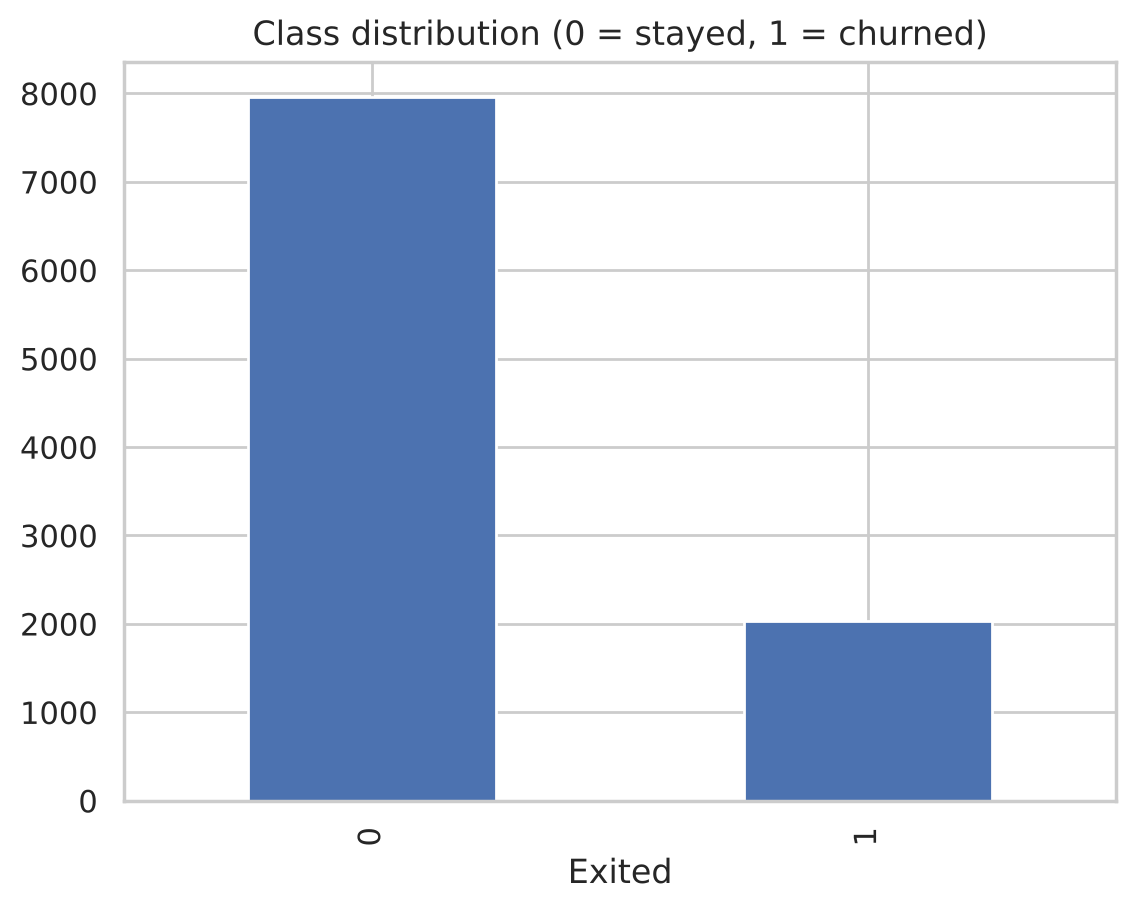

In [2]:
churn = churn.drop(columns=["RowNumber", "CustomerId", "Surname"])
X = churn.drop(columns="Exited")
y = churn["Exited"]

print(f"Churn rate: {y.mean():.1%}")
y.value_counts().plot.bar(title="Class distribution (0 = stayed, 1 = churned)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

فقط حدود ۲۰٪ مشتریان ریزش کرده‌اند؛ یعنی داده **نامتوازن** است. مدلی که همیشه بگوید «ریزش نمی‌کند» دقت ۸۰٪ دارد و کاملاً بی‌فایده است. پس از ابتدا معیار اصلی را مشخص می‌کنیم: چون هدف پیدا کردن مشتریان در معرض ریزش است، **Recall** و **F1** کلاس ۱ و **Average Precision** (سطح زیر منحنی Precision-Recall) را دنبال می‌کنیم.

</div>

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

numeric = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
categorical = ["Geography", "Gender"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical),
])

def make_logreg(**kwargs):
    return Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000, **kwargs))])

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. چرا یک بار تقسیم کافی نیست؟

نتیجهٔ ارزیابی به اینکه کدام نمونه‌ها در بخش آزمون قرار گیرند بستگی دارد. همان مدل را با ۲۰ تقسیم تصادفی متفاوت ارزیابی می‌کنیم:

</div>

In [4]:
from sklearn.metrics import f1_score

scores = []
for seed in range(20):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    scores.append(f1_score(yb, make_logreg().fit(Xa, ya).predict(Xb)))

print(f"F1 over 20 random splits: min={min(scores):.3f}  max={max(scores):.3f}  std={np.std(scores):.3f}")

F1 over 20 random splits: min=0.270  max=0.368  std=0.022


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

F1 بسته به تقسیم، تغییر قابل توجهی دارد. اگر دو مدل را فقط با یک تقسیم مقایسه کنیم، ممکن است تفاوت ناشی از **شانس** را به حساب برتری مدل بگذاریم.

## ۳. اعتبارسنجی متقابل K-Fold

در **K-Fold Cross-Validation**:
1. دادهٔ آموزش به $K$ بخش (fold) مساوی تقسیم می‌شود.
2. مدل $K$ بار آموزش می‌بیند؛ هر بار یک بخش برای اعتبارسنجی و $K-1$ بخش دیگر برای آموزش.
3. میانگین (و انحراف معیار) $K$ امتیاز گزارش می‌شود.

هر نمونه دقیقاً یک بار در اعتبارسنجی حضور دارد. مقادیر رایج $K$، ۵ و ۱۰ هستند.

**Stratified K-Fold** نسبت کلاس‌ها را در همهٔ بخش‌ها حفظ می‌کند و برای طبقه‌بندی، به‌خصوص با دادهٔ نامتوازن، ضروری است. scikit-learn برای طبقه‌بندی به‌طور پیش‌فرض از آن استفاده می‌کند.

</div>

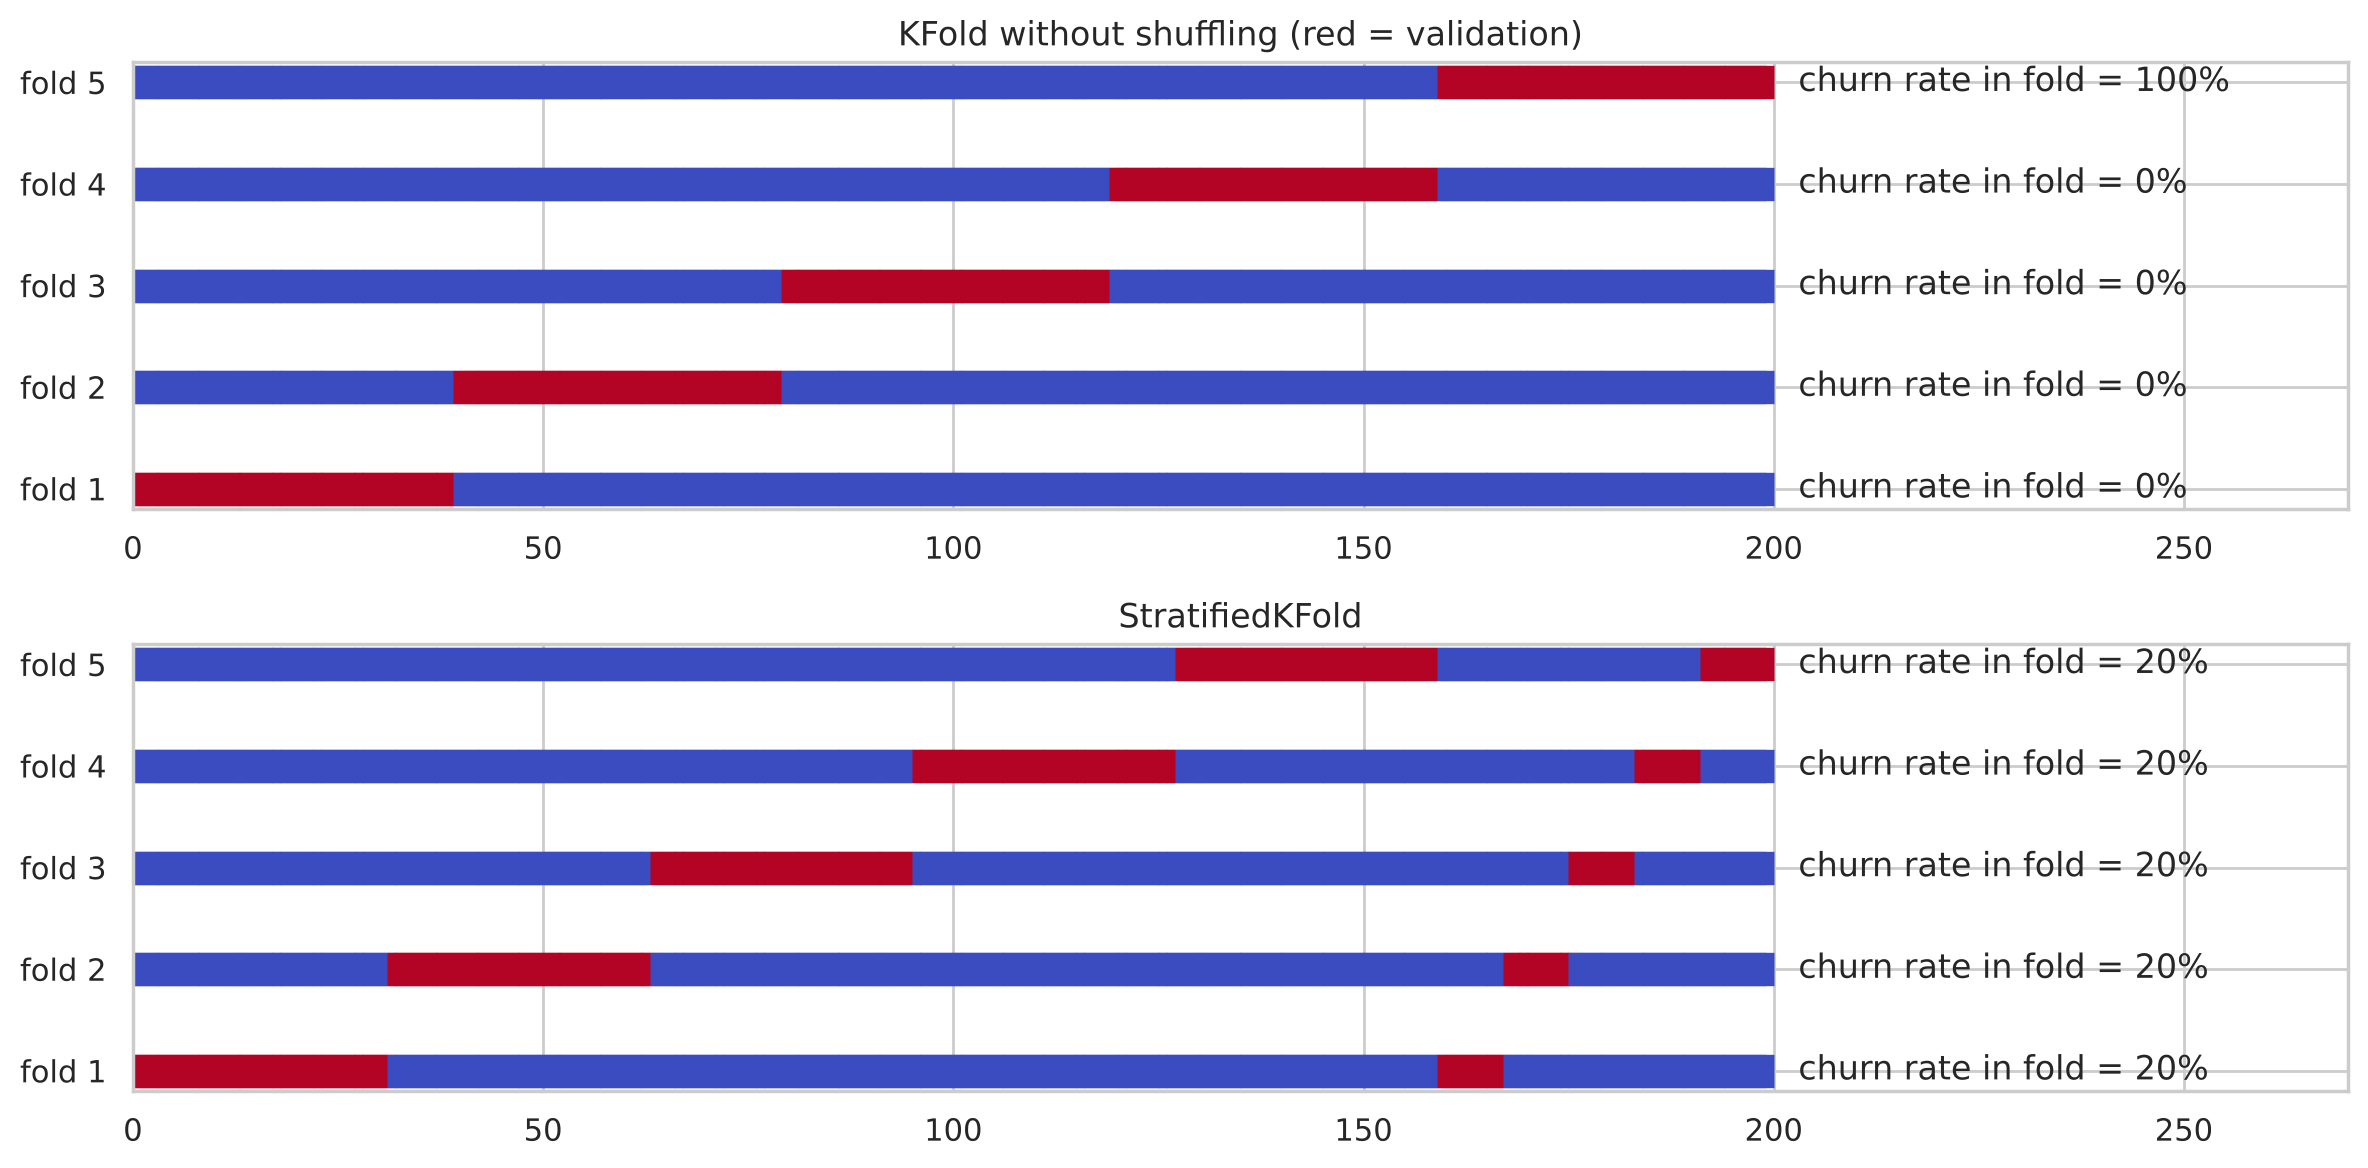

In [5]:
from sklearn.model_selection import KFold, StratifiedKFold

def plot_cv_splits(cv, X, y, ax, title):
    for i, (train_idx, val_idx) in enumerate(cv.split(X, y)):
        indices = np.full(len(X), np.nan)
        indices[train_idx], indices[val_idx] = 0, 1
        ax.scatter(range(len(X)), [i] * len(X), c=indices, cmap="coolwarm", marker="_", lw=12, vmin=0, vmax=1)
        rate = y.iloc[val_idx].mean()
        ax.text(len(X) + 3, i, f"churn rate in fold = {rate:.0%}", va="center")
    ax.set_yticks(range(5), [f"fold {i + 1}" for i in range(5)])
    ax.set_title(title)
    ax.set_xlim(0, len(X) * 1.35)

sample_y = y_train.sort_values().iloc[::40].reset_index(drop=True)     # sorted on purpose to show the problem
sample_X = pd.DataFrame(index=sample_y.index)
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
plot_cv_splits(KFold(5), sample_X, sample_y, axes[0], "KFold without shuffling (red = validation)")
plot_cv_splits(StratifiedKFold(5), sample_X, sample_y, axes[1], "StratifiedKFold")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در این مثال عمداً داده را بر اساس برچسب مرتب کرده‌ایم. `KFold` ساده بخش‌هایی با نرخ ریزش کاملاً متفاوت می‌سازد (بعضی بدون هیچ مشتری ریزشی!)، ولی `StratifiedKFold` نرخ را در همهٔ بخش‌ها یکسان نگه می‌دارد.

با `cross_validate` می‌توانیم چند معیار را هم‌زمان حساب کنیم:

</div>

In [6]:
from sklearn.model_selection import cross_validate, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

cv_results = cross_validate(make_logreg(), X_train, y_train, cv=cv, scoring=metrics)
pd.DataFrame({m: cv_results[f"test_{m}"] for m in metrics}).describe().loc[["mean", "std"]].round(3)

,accuracy,precision,recall,f1,roc_auc,average_precision
mean,0.810,0.597,0.214,0.315,0.763,0.469
std,0.007,0.050,0.029,0.037,0.022,0.034


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

رگرسیون لجستیک دقت حدود ۸۱٪ دارد که فقط کمی بیشتر از مدل پایهٔ ۸۰٪ است، و **Recall حدود ۲۰٪**؛ یعنی از هر ۵ مشتری ریزشی فقط یکی را پیدا می‌کند! این همان مشکل دادهٔ نامتوازن است.

### انواع خاص اعتبارسنجی

| روش | کاربرد |
|---|---|
| `StratifiedKFold` | طبقه‌بندی (پیش‌فرض) |
| `RepeatedStratifiedKFold` | تکرار K-Fold با بُرزدن‌های مختلف؛ تخمین پایدارتر |
| `LeaveOneOut` | دادهٔ بسیار کوچک؛ هر بار یک نمونه برای اعتبارسنجی |
| `GroupKFold` | وقتی چند نمونه به یک گروه تعلق دارند (مثلاً چند تصویر از یک بیمار)؛ همهٔ نمونه‌های یک گروه باید در یک طرف باشند تا نشت رخ ندهد |
| `TimeSeriesSplit` | **دادهٔ زمانی**: همیشه با گذشته آموزش و با آینده ارزیابی کن؛ هرگز دادهٔ زمانی را تصادفی بُر نزنید |

## ۴. تنظیم ابرپارامتر

- **پارامتر:** چیزی که مدل از داده یاد می‌گیرد؛ مثل ضرایب رگرسیون.
- **ابرپارامتر (Hyperparameter):** چیزی که ما قبل از آموزش تعیین می‌کنیم؛ مثل `C`، `max_depth` یا نرخ یادگیری.

### ۴.۱ جستجوی شبکه‌ای (Grid Search)

همهٔ ترکیب‌های مقادیر داده‌شده را با اعتبارسنجی متقابل امتحان می‌کند. چون پیش‌پردازش داخل Pipeline است، در هر بخش دوباره `fit` می‌شود و نشتی رخ نمی‌دهد. نام پارامترها به شکل `step__parameter` است.

</div>

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

hgb_pipe = Pipeline([("prep", preprocessor), ("model", HistGradientBoostingClassifier(random_state=42))])

param_grid = {
    "model__learning_rate": [0.03, 0.1, 0.3],
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [20, 50],
}
grid = GridSearchCV(hgb_pipe, param_grid, cv=cv, scoring="average_precision", n_jobs=-1)
grid.fit(X_train, y_train)

print("Combinations tried:", len(grid.cv_results_["params"]))
print("Best parameters:", grid.best_params_)
print(f"Best CV average precision: {grid.best_score_:.3f}")

Combinations tried: 18
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 20}
Best CV average precision: 0.699


In [8]:
cols = ["param_model__learning_rate", "param_model__max_depth", "param_model__min_samples_leaf",
        "mean_test_score", "std_test_score", "rank_test_score"]
pd.DataFrame(grid.cv_results_)[cols].sort_values("rank_test_score").head(8).round(4)

,param_model__learning_rate,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
6,0.10,3,20,0.6986,0.0223,1
7,0.10,3,50,0.6976,0.0229,2
9,0.10,5,50,0.6967,0.0241,3
8,0.10,5,20,0.6963,0.0264,4
13,0.30,3,50,0.6960,0.0275,5
5,0.03,None,50,0.6944,0.0261,6
4,0.03,None,20,0.6934,0.0261,7
12,0.30,3,20,0.6934,0.0258,8


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### ۴.۲ جستجوی تصادفی (Randomized Search)

با افزایش تعداد ابرپارامترها، تعداد ترکیب‌های Grid Search به‌صورت نمایی زیاد می‌شود. **Randomized Search** به‌جای امتحان همهٔ ترکیب‌ها، تعداد مشخصی ترکیب را **به‌طور تصادفی از توزیع‌ها** نمونه می‌گیرد. تحقیقات نشان داده که با بودجهٔ محاسباتی برابر، معمولاً به نتیجهٔ بهتر یا برابر می‌رسد، چون مقادیر بیشتری از ابرپارامترهای مهم را امتحان می‌کند.

</div>

In [9]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

param_distributions = {
    "model__learning_rate": loguniform(0.01, 0.5),
    "model__max_depth": [3, 4, 5, 6, 8, None],
    "model__min_samples_leaf": randint(10, 100),
    "model__l2_regularization": loguniform(1e-3, 10),
    "model__max_iter": randint(100, 500),
}
random_search = RandomizedSearchCV(hgb_pipe, param_distributions, n_iter=30, cv=cv,
                                   scoring="average_precision", n_jobs=-1, random_state=42)
random_search.fit(X_train, y_train)

print("Best parameters:", {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in random_search.best_params_.items()})
print(f"Best CV average precision: {random_search.best_score_:.3f}")

Best parameters: {'model__l2_regularization': 0.244, 'model__learning_rate': 0.0572, 'model__max_depth': 5, 'model__max_iter': 187, 'model__min_samples_leaf': 33}
Best CV average precision: 0.697


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

اینجا هر دو روش به امتیاز تقریباً یکسانی رسیدند؛ ولی Randomized Search پنج ابرپارامتر را هم‌زمان جستجو کرد، که با Grid Search به صدها ترکیب نیاز داشت.

ابزارهای پیشرفته‌تر مثل **Optuna** از بهینه‌سازی بیزی استفاده می‌کنند: از نتیجهٔ آزمایش‌های قبلی یاد می‌گیرند تا ترکیب بعدی را هوشمندانه‌تر انتخاب کنند.

## ۵. اعتبارسنجی متقابل تودرتو (Nested CV)

یک نکتهٔ ظریف: `best_score_` تخمینی **خوش‌بینانه** است، چون بهترین ترکیب را دقیقاً بر اساس همین امتیاز انتخاب کرده‌ایم. وقتی ده‌ها ترکیب را امتحان کنیم، احتمال دارد یکی فقط از روی شانس امتیاز بالایی گرفته باشد.

برای تخمین بی‌طرفانهٔ عملکرد **کل فرایند** (شامل جستجوی ابرپارامتر)، از **Nested CV** استفاده می‌کنیم:
- **حلقهٔ بیرونی:** داده را به بخش‌هایی برای ارزیابی نهایی تقسیم می‌کند.
- **حلقهٔ درونی:** در هر بخش بیرونی، جستجوی ابرپارامتر را فقط روی دادهٔ آموزش آن بخش انجام می‌دهد.

</div>

In [10]:
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

small_grid = GridSearchCV(hgb_pipe, {"model__learning_rate": [0.03, 0.1, 0.3], "model__max_depth": [3, None]},
                          cv=inner_cv, scoring="average_precision", n_jobs=-1)
small_grid.fit(X_train, y_train)
nested_scores = cross_val_score(small_grid, X_train, y_train, cv=outer_cv, scoring="average_precision")

print(f"Non-nested (best_score_) estimate: {small_grid.best_score_:.3f}")
print(f"Nested CV estimate:                {nested_scores.mean():.3f} ± {nested_scores.std():.3f}")

Non-nested (best_score_) estimate: 0.700
Nested CV estimate:                0.704 ± 0.012


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در این مثال دو تخمین تقریباً برابرند (حتی تخمین تودرتو کمی بالاتر است)؛ یعنی چون فضای جستجو کوچک و داده نسبتاً زیاد است، خوش‌بینی محسوسی نداشتیم. ولی با فضای جستجوی بزرگ و دادهٔ کم، این تفاوت می‌تواند قابل توجه باشد. وقتی می‌خواهید عملکرد را در یک **مقاله** یا گزارش رسمی اعلام کنید، از Nested CV یا یک دادهٔ آزمون کاملاً جداگانه که هرگز در انتخاب‌ها نقشی نداشته استفاده کنید.

## ۶. کار با دادهٔ نامتوازن

راه‌حل‌های اصلی:

1. **معیار مناسب:** Recall، Precision، F1 و Average Precision به‌جای accuracy.
2. **وزن‌دهی کلاس‌ها (`class_weight="balanced"`):** خطا روی کلاس اقلیت جریمهٔ بیشتری می‌گیرد. ساده‌ترین و اغلب مؤثرترین راه.
3. **بازنمونه‌گیری (Resampling):**
   - **Undersampling:** حذف تصادفی بخشی از کلاس اکثریت.
   - **Oversampling:** تکرار نمونه‌های کلاس اقلیت.
   - **SMOTE:** ساختن نمونه‌های **مصنوعی** جدید برای کلاس اقلیت با درون‌یابی بین نمونه‌های نزدیک به هم.
4. **تنظیم آستانهٔ تصمیم:** مثل جلسهٔ ۵.

**هشدار بسیار مهم:** بازنمونه‌گیری باید **فقط روی دادهٔ آموزش** انجام شود. اگر SMOTE را قبل از تقسیم یا قبل از اعتبارسنجی متقابل اجرا کنید، نمونه‌های مصنوعی ساخته‌شده از دادهٔ اعتبارسنجی به آموزش نشت می‌کنند. کتابخانهٔ `imbalanced-learn` یک `Pipeline` مخصوص دارد که بازنمونه‌گیری را فقط هنگام `fit` اعمال می‌کند.

</div>

In [11]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.base import clone

candidates = {
    "LogReg": make_logreg(),
    "LogReg + class_weight": make_logreg(class_weight="balanced"),
    "LogReg + SMOTE": ImbPipeline([("prep", preprocessor), ("smote", SMOTE(random_state=42)),
                                   ("model", LogisticRegression(max_iter=1000))]),
    "HistGB (tuned)": random_search.best_estimator_,
    "HistGB (tuned) + class_weight": clone(random_search.best_estimator_).set_params(model__class_weight="balanced"),
}

rows = []
for name, model in candidates.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=["precision", "recall", "f1", "average_precision"], n_jobs=-1)
    rows.append({"model": name, **{m: res[f"test_{m}"].mean() for m in ["precision", "recall", "f1", "average_precision"]}})
comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison

,precision,recall,f1,average_precision
model,,,,
LogReg,0.597,0.214,0.315,0.469
LogReg + class_weight,0.380,0.685,0.488,0.457
LogReg + SMOTE,0.383,0.681,0.490,0.456
HistGB (tuned),0.761,0.480,0.589,0.697
HistGB (tuned) + class_weight,0.524,0.734,0.611,0.698


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نتایج مهم:
- وزن‌دهی کلاس و SMOTE، Recall رگرسیون لجستیک را از حدود ۲۰٪ به حدود ۷۰٪ می‌رسانند، به قیمت کاهش Precision. هر دو روش نتیجهٔ تقریباً مشابهی دارند؛ وزن‌دهی ساده‌تر است و دادهٔ مصنوعی نمی‌سازد.
- **Average Precision** با وزن‌دهی یا SMOTE تقریباً تغییر نمی‌کند. چرا؟ چون این معیار کیفیت **رتبه‌بندی** را مستقل از آستانه می‌سنجد. این روش‌ها عمدتاً آستانهٔ مؤثر را جابه‌جا می‌کنند، نه اینکه مدل را واقعاً بهتر کنند.
- مدل HistGradientBoosting در همهٔ معیارها از رگرسیون لجستیک بهتر است؛ **مدل بهتر** مهم‌تر از ترفندهای بازنمونه‌گیری است.

### ۶.۱ تنظیم آستانه به روش درست

به‌جای بازنمونه‌گیری، می‌توان مدل اصلی را نگه داشت و فقط **آستانه** را عوض کرد. `TunedThresholdClassifierCV` آستانه‌ای را پیدا می‌کند که یک معیار (مثلاً F1) را با اعتبارسنجی متقابل روی دادهٔ **آموزش** بیشینه کند:

</div>

In [12]:
best_hgb = random_search.best_estimator_
tuned = TunedThresholdClassifierCV(best_hgb, scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)
print(f"Best threshold found by CV: {tuned.best_threshold_:.3f}  (CV F1 = {tuned.best_score_:.3f})")

Best threshold found by CV: 0.283  (CV F1 = 0.625)


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۷. ارزیابی نهایی روی دادهٔ آزمون

تا اینجا به دادهٔ آزمون **دست نزده‌ایم**. همهٔ انتخاب‌ها (مدل، ابرپارامترها و آستانه) فقط با اعتبارسنجی متقابل روی دادهٔ آموزش انجام شد. حالا و **فقط یک بار**، مدل نهایی را روی دادهٔ آزمون ارزیابی می‌کنیم:

</div>

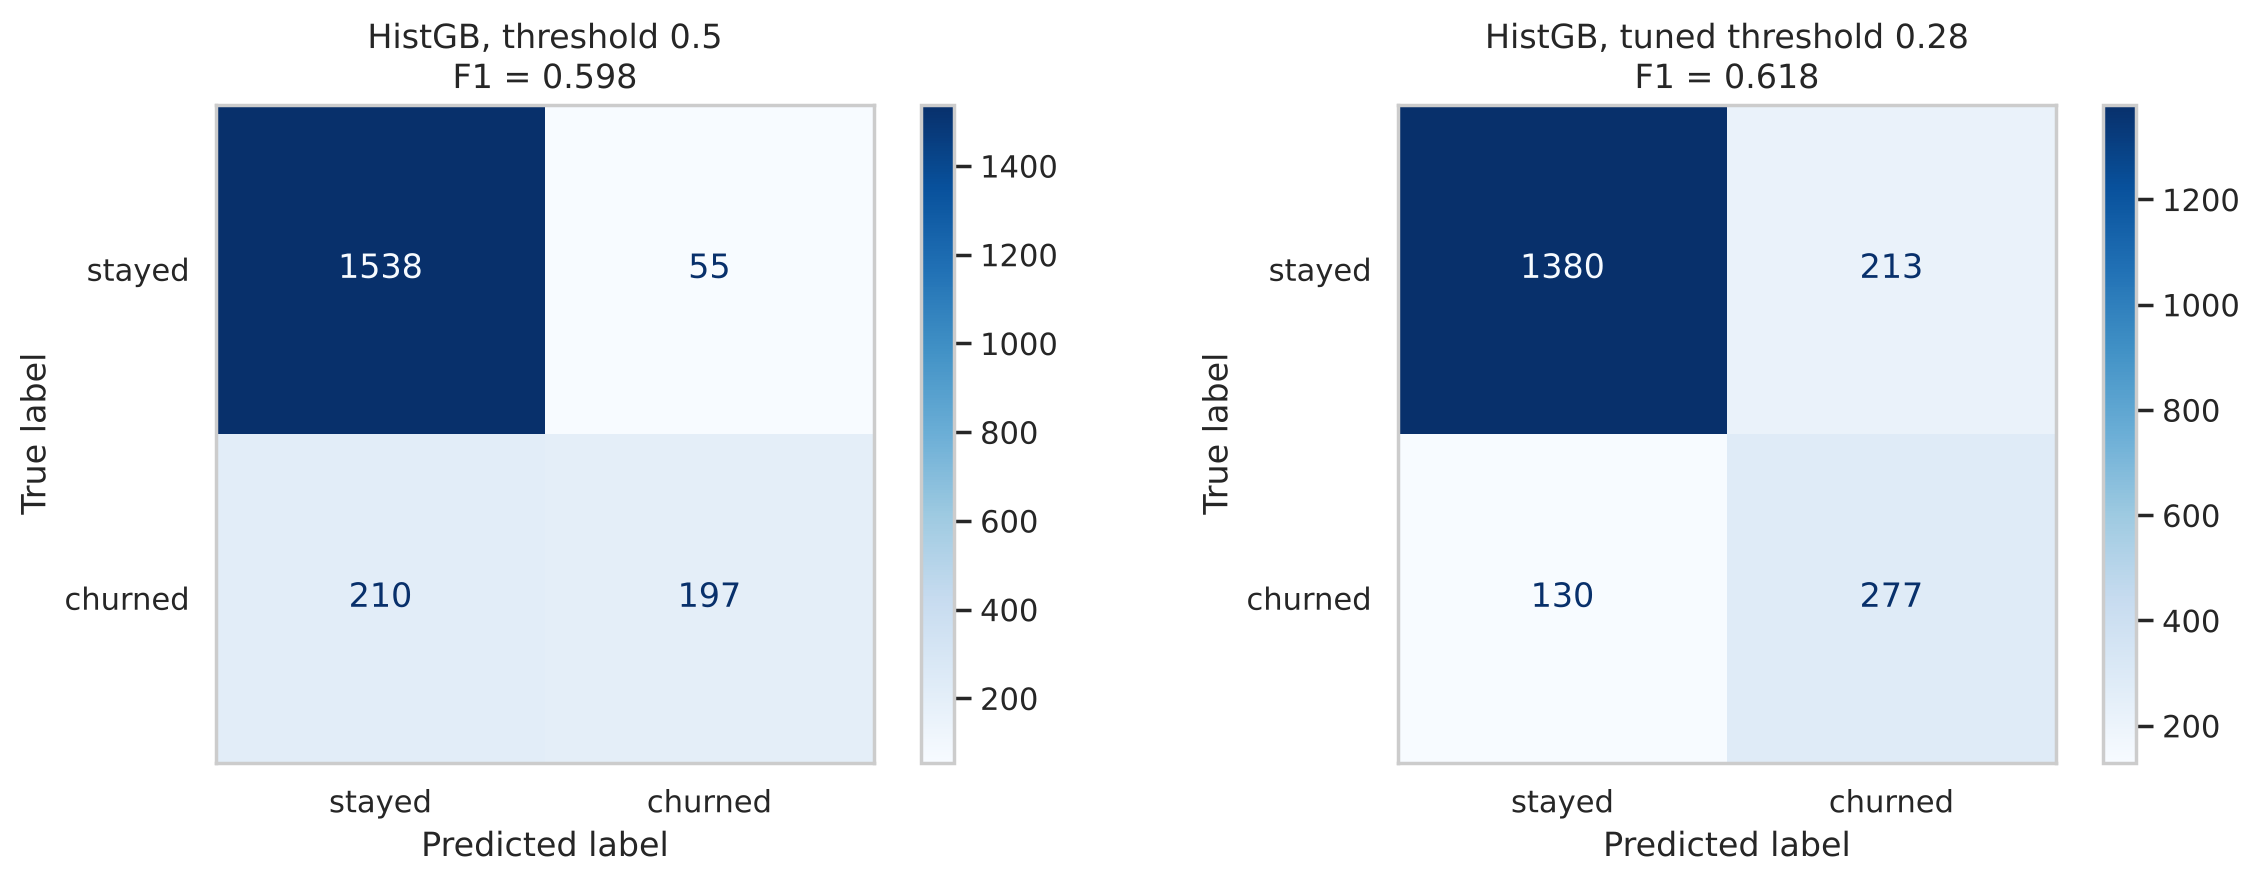

              precision    recall  f1-score   support

      stayed      0.914     0.866     0.889      1593
     churned      0.565     0.681     0.618       407

    accuracy                          0.829      2000
   macro avg      0.740     0.773     0.754      2000
weighted avg      0.843     0.829     0.834      2000

Test average precision: 0.714


In [13]:
from sklearn.metrics import classification_report, average_precision_score, ConfusionMatrixDisplay

final_models = {"HistGB, threshold 0.5": best_hgb, f"HistGB, tuned threshold {tuned.best_threshold_:.2f}": tuned}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, model) in zip(axes, final_models.items()):
    pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["stayed", "churned"], cmap="Blues", ax=ax)
    ax.grid(False)
    ax.set_title(f"{name}\nF1 = {f1_score(y_test, pred):.3f}")
plt.tight_layout()
plt.show()

print(classification_report(y_test, tuned.predict(X_test), target_names=["stayed", "churned"], digits=3))
print(f"Test average precision: {average_precision_score(y_test, best_hgb.predict_proba(X_test)[:, 1]):.3f}")

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با آستانهٔ تنظیم‌شده، مدل تعداد بسیار بیشتری از مشتریان ریزشی را پیدا می‌کند و F1 بهتر می‌شود. انتخاب نهایی آستانه، در دنیای واقعی، باید با تیم کسب‌وکار و بر اساس هزینهٔ تماس با مشتری در برابر ارزش نگه داشتن او انجام شود.

## جمع‌بندی

1. دادهٔ آزمون را در ابتدا کنار بگذارید و تا پایان به آن دست نزنید.
2. معیار ارزیابی را بر اساس هدف کسب‌وکار انتخاب کنید (برای دادهٔ نامتوازن، accuracy کافی نیست).
3. همهٔ پیش‌پردازش‌ها و بازنمونه‌گیری را داخل **Pipeline** بگذارید.
4. مدل‌ها را با **اعتبارسنجی متقابل Stratified** و تقسیم‌های یکسان مقایسه کنید.
5. ابرپارامترها را با Grid یا Randomized Search تنظیم کنید.
6. در صورت نیاز آستانه را با اعتبارسنجی متقابل تنظیم کنید.
7. در پایان، **یک بار** روی دادهٔ آزمون ارزیابی کنید و برای گزارش رسمی Nested CV را در نظر بگیرید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. `RandomForestClassifier` را با `RandomizedSearchCV` روی همین داده تنظیم کنید و با HistGradientBoosting مقایسه کنید.

۲. به‌جای SMOTE از `RandomUnderSampler` در `imblearn` استفاده کنید. نتیجه چه تفاوتی دارد؟

۳. فرض کنید تماس با هر مشتری ۱۰ واحد هزینه دارد و نگه داشتن یک مشتری ریزشی ۱۰۰ واحد سود. با یک تابع امتیاز سفارشی (`make_scorer`) آستانه‌ای را پیدا کنید که سود را بیشینه کند.

۴. ویژگی‌های جدیدی بسازید (مثلاً نسبت `Balance` به `EstimatedSalary` یا اینکه موجودی صفر است یا نه) و ببینید Average Precision بهتر می‌شود یا نه.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** `RandomForestClassifier` را با `RandomizedSearchCV` روی همین داده تنظیم کنید و با HistGradientBoosting مقایسه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** به‌جای SMOTE از `RandomUnderSampler` در `imblearn` استفاده کنید. نتیجه چه تفاوتی دارد؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** فرض کنید تماس با هر مشتری ۱۰ واحد هزینه دارد و نگه داشتن یک مشتری ریزشی ۱۰۰ واحد سود. با یک تابع امتیاز سفارشی (`make_scorer`) آستانه‌ای را پیدا کنید که سود را بیشینه کند.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** ویژگی‌های جدیدی بسازید (مثلاً نسبت `Balance` به `EstimatedSalary` یا اینکه موجودی صفر است یا نه) و ببینید Average Precision بهتر می‌شود یا نه.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
